## 1) Lab 5  
**Association Mining and Sequence Analysis in Python: Market-Basket Rules + Sequential Patterns (Online Retail)**

## 2) Learning Objectives
By the end of this lab, you will be able to:

1. **Load** a real transactional dataset and **validate** schema, types, and basic quality constraints (duplicates, cancellations, missingness).
2. **Transform** invoice-line data into (a) transaction baskets for association mining and (b) ordered customer sequences for sequential mining.
3. **Implement** frequent itemset mining using **`mlxtend.frequent_patterns.apriori`** and **compare** with **`mlxtend.frequent_patterns.fpgrowth`** for scalability tradeoffs.
4. **Generate** association rules with **`mlxtend.frequent_patterns.association_rules`** and **interpret** support, confidence, and lift for business value and statistical caution.
5. **Diagnose** rule sets using visual analytics (support–confidence scatter; lift distribution) and **identify** misleading “high-confidence” rules driven by popular items.
6. **Mine** frequent sequential patterns using **PrefixSpan** and **derive** simple sequential rules (prefix → next event) with support/confidence/lift.
7. **Evaluate** discovered patterns for **deployment readiness**: leakage risks, monitoring signals, cost/latency implications, and ethical concerns.

## 3) Tasks
- Validate the Online Retail dataset schema and clean transactional anomalies.
- Build invoice-level baskets and one-hot encode for frequent itemset mining.
- Mine frequent itemsets with Apriori; generate and filter association rules by lift.
- Visualize transactions (binary matrix “image”) and visualize rules (support vs confidence).
- Compare Apriori vs FP-Growth runtime and discuss systems tradeoffs.
- Construct customer purchase sequences ordered by time; mine frequent sequential patterns via PrefixSpan.
- Convert frequent patterns into sequential rules; interpret support/confidence/lift.
- Produce a short “production checklist” for deploying a rule engine (validation + monitoring).

---

## 4) References
### Official Documentation
- `mlxtend.frequent_patterns.apriori` user guide: https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/
- `mlxtend.frequent_patterns.association_rules` user guide: https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/
- `pandas.get_dummies` API: https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html
- UCI Online Retail dataset page (metadata + license CC BY 4.0): https://archive.ics.uci.edu/dataset/352/online%2Bretail
- `prefixspan` (PyPI): https://pypi.org/project/prefixspan/

### References 
- Spark PrefixSpan API (industry-scale perspective): https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.fpm.PrefixSpan.html

### Python Commands / Quick Reference
- `pandas.read_excel`, `DataFrame.dropna`, `DataFrame.groupby`, `DataFrame.sort_values`
- `pandas.get_dummies`
- `mlxtend.frequent_patterns.apriori`, `mlxtend.frequent_patterns.fpgrowth`, `mlxtend.frequent_patterns.association_rules`
- `matplotlib.pyplot.imshow`, `matplotlib.pyplot.scatter`, `matplotlib.pyplot.hist`
- `prefixspan.PrefixSpan`

---

## 5) Workflow Overview
1. Setup & reproducibility  
2. Data acquisition (Online Retail)  
3. Data validation & cleaning (schema + anomalies)  
4. Basket construction + one-hot encoding  
5. Baseline frequent itemsets (Apriori)  
6. Rule generation + diagnostics (support/confidence/lift + plots)  
7. Improvement step: FP-Growth + threshold tuning + systems comparison  
8. Sequence construction (customer timelines)  
9. Sequential pattern mining (PrefixSpan) + sequential rules  
10. Systems discussion: deployment checklist, monitoring, ethics, reporting

**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.

## 6) Lab Instructions (Step-by-step)

### Step 1 — Setup & reproducibility

### Coding questions
1) What would make your results *non-reproducible* across machines/runs in this lab (think: sampling, ordering, library versions)?  

Results can differ because of random sampling, inconsistent transaction ordering, different pandas/mlxtend/prefixspan versions, different preprocessing choices, and different support/confidence thresholds. A reproducible run should record the random seed, library versions, dataset version or URL, cleaning rules, thresholds, and sorting rules.

2) For association rules, why might simply changing the *sorting order of transactions* change your outputs if you are not careful? 

Changing transaction order should not change correctly calculated support, confidence, or lift because these metrics depend on set membership, not row order. However, order can matter if code uses position-based sampling, cumulative operations, sequence mining, or an unstable preprocessing step. Sorting explicitly before sequence construction prevents accidental differences.

In [1]:
%pip install mlxtend

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
%pip install -q mlxtend prefixspan ucimlrepo
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlxtend
from prefixspan import PrefixSpan  # type: ignore[import-not-found]
import ucimlrepo

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("mlxtend:", mlxtend.__version__)
print("prefixspan: installed")
print("ucimlrepo: installed")

Note: you may need to restart the kernel to use updated packages.
Python: 3.13.9
NumPy: 2.5.3
Pandas: 2.3.3
mlxtend: 0.25.0
prefixspan: installed
ucimlrepo: installed


### Execution interpretation questions
1) Which versions would you log in an experiment tracker to reproduce results later?    

At minimum I would log Python, pandas, NumPy, mlxtend, and prefixspan versions, plus the operating system. I would also record the dataset version, cleaning rules, random seed, and all mining thresholds.

2) If two students get different rule sets, what is your first hypothesis to test?  

My first hypothesis would be that the students used different data or preprocessing. I would compare dataset version, cancellation handling, missing-value handling, item representation, transaction definition, min_support, min_confidence, min_lift, and random sampling before investigating algorithm differences.

**Think like an ML Systems engineer**  
- Write down *exactly* what you would store as “run metadata” (seed, code commit hash, dataset DOI/URL, thresholds).    
Store the random seed, Python and package versions, dataset URL/version and checksum, code or notebook version, cleaning rules, transaction definition, item identifier, top-K value, support/confidence/lift thresholds, maximum itemset length, sequence event definition, PrefixSpan support threshold, and timestamps for the run.

### Step 2 — Data acquisition (real dataset + metadata)

**Dataset requirement (mandatory)**
- **Primary dataset:** UCI **Online Retail** (invoice-line transactions). License: **CC BY 4.0**.  
  Dataset page: https://archive.ics.uci.edu/dataset/352/online%2Bretail
- **Load option (recommended):** programmatically fetch via `ucimlrepo` (repeatable).
- **Fallback dataset:** UCI **Online Retail II**: https://archive.ics.uci.edu/ml/datasets/online%2Bretail%2BII

### Coding questions
1) Why is invoice-line format not immediately usable for Apriori? What transformation is required?      
Invoice-line data has one row per item on an invoice, while Apriori expects each transaction to be represented as a set of items. The rows must therefore be grouped by invoice, duplicate items within a basket removed, and the result transformed into a transaction-by-item binary matrix.

2) What rows would you consider “invalid transactions” for market-basket mining in this dataset and why?    
Cancellation invoices, rows with non-positive quantities, missing item descriptions, and unusable invoice identifiers should be excluded from a purchase basket. Cancellation and negative-quantity rows represent returns or reversals rather than purchases, while missing item identifiers cannot reliably become basket items.

### Function/class selection and parameter exploration
- Use: `ucimlrepo.fetch_ucirepo` (or `pandas.read_excel`)
- Explore parameters: if using `read_excel`, explore `dtype`, `parse_dates`, and explain how date parsing affects sequence ordering.

In [3]:
# If needed:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)  # UCI Online Retail

df = online_retail.data.features.copy()
if "InvoiceNo" not in df.columns and online_retail.data.ids is not None:
    ids = online_retail.data.ids
    for col in ids.columns:
        if col not in df.columns:
            df[col] = ids[col].values

# Pandas 3.0 infers StringDtype by default; convert to object for compatibility
# with np.issubdtype, pd.crosstab, and mlxtend internals.
for col in df.columns:
    if pd.api.types.is_string_dtype(df[col]) and df[col].dtype != "object":
        df[col] = df[col].astype("object")

print(df.shape)
print(df.head(3))

# Basic metadata (useful for provenance logging)
print("\nMetadata keys:", list(online_retail.metadata.keys())[:8])

(541909, 8)
                          Description  Quantity     InvoiceDate  UnitPrice  CustomerID         Country InvoiceNo  \
0  WHITE HANGING HEART T-LIGHT HOLDER         6  12/1/2010 8:26       2.55     17850.0  United Kingdom    536365   
1                 WHITE METAL LANTERN         6  12/1/2010 8:26       3.39     17850.0  United Kingdom    536365   
2      CREAM CUPID HEARTS COAT HANGER         8  12/1/2010 8:26       2.75     17850.0  United Kingdom    536365   

  StockCode  
0    85123A  
1     71053  
2    84406B  

Metadata keys: ['uci_id', 'name', 'repository_url', 'data_url', 'abstract', 'area', 'tasks', 'characteristics']


In [4]:
# Print a concise schema summary
print("Schema summary:")
print(df.dtypes)
print("\nColumns:" , list(df.columns))

# Identify which columns are needed for baskets and sequences
basket_columns = ["InvoiceNo", "Description"]  # or StockCode
sequence_columns = ["CustomerID", "InvoiceDate", "StockCode", "InvoiceNo"]  # include InvoiceNo as event boundary

print("\nColumns needed for baskets:", basket_columns)
print("Columns needed for sequences:", sequence_columns)

Schema summary:
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
InvoiceNo       object
StockCode       object
dtype: object

Columns: ['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'InvoiceNo', 'StockCode']

Columns needed for baskets: ['InvoiceNo', 'Description']
Columns needed for sequences: ['CustomerID', 'InvoiceDate', 'StockCode', 'InvoiceNo']


### Execution questions
1) Which field would you prefer as the “item id” in production: `StockCode` or `Description`? Why?  
I would prefer `StockCode` in production because it is intended to identify a product and is less vulnerable to spelling, capitalization, and description changes. `Description` is easier to interpret in a classroom analysis, but descriptions can change or contain inconsistent text.

2) What is one risk of using a dataset fetch utility in production pipelines?   
A fetch utility can introduce reproducibility and availability risks if the remote dataset changes, disappears, becomes temporarily unavailable, or is returned in a different format. A production pipeline should pin a dataset version and retain a checksum or immutable snapshot.


**Think like an ML Systems engineer**  
- Record the dataset DOI / citation and license in your run report.

### Step 3 — Data validation & cleaning

#### Coding questions
1) What failure mode happens if cancellations/refunds remain in the basket data?    
If cancellations and refunds remain in the baskets, products may appear to have been purchased together when some rows actually represent returns. This can distort support and create misleading association rules.

2) How could missing `CustomerID` affect sequence mining?   
Missing `CustomerID` prevents reliable grouping of events into customer timelines. If unidentified rows were combined, purchases from different people could be incorrectly treated as one sequence.

3) Why might negative/zero `Quantity` be problematic for “items purchased”?     
Negative or zero quantities do not represent positive purchases. Including them can create false basket membership and distort product frequencies, support, and sequential patterns.

#### Function/class selection and parameter exploration
- Use: `DataFrame.isna`, `DataFrame.duplicated`, `DataFrame.query`, `DataFrame.astype`, `pd.to_datetime`  
- Explore: `pd.to_datetime(..., errors=..., utc=...)` and discuss time zone consistency for ordering events.

In [5]:
# Normalize key columns
required_cols = ["InvoiceNo", "Description", "Quantity", "InvoiceDate", "CustomerID"]
missing = [c for c in required_cols if c not in df.columns]
print("Missing required cols:", missing)

# Parse dates robustly
if not pd.api.types.is_datetime64_any_dtype(df["InvoiceDate"]):
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

print("Rows with invalid dates:", df["InvoiceDate"].isna().sum())
print("Rows with missing CustomerID:", df["CustomerID"].isna().sum())

Missing required cols: []
Rows with invalid dates: 0
Rows with missing CustomerID: 135080


In [6]:
# Identify cancellations: InvoiceNo starting with 'C'
df["InvoiceNo_str"] = df["InvoiceNo"].astype(str)
is_cancel = df["InvoiceNo_str"].str.startswith("C")

# Clean rules for this lab:
# - Keep only positive quantities
# - Remove cancellations
# - Drop missing CustomerID for sequence mining

basket_df = df.loc[(~is_cancel) & (df["Quantity"] > 0)].copy()
seq_df = basket_df.dropna(subset=["CustomerID", "InvoiceDate", "Description"]).copy()

print("basket_df shape:", basket_df.shape)
print("seq_df shape:", seq_df.shape)

basket_df shape: (531285, 9)
seq_df shape: (397924, 9)


In [7]:
# Data-quality check 1: Assert very few missing Descriptions in basket_df
desc_missing_ratio = basket_df["Description"].isna().mean()
assert desc_missing_ratio < 0.01, (
    f"Too many missing Descriptions in basket_df: {desc_missing_ratio:.3%}")

# Data-quality check 2: Assert InvoiceDate is monotonic per CustomerID in seq_df
seq_sorted = seq_df.sort_values(["CustomerID", "InvoiceDate"])
monotonic_props = seq_sorted.groupby("CustomerID")["InvoiceDate"].apply(lambda s: s.is_monotonic_increasing)
monotonic_ratio = monotonic_props.mean()
assert monotonic_ratio > 0.99, (
    f"Too many customers with non-monotonic InvoiceDates: only {monotonic_ratio:.2%} monotonic.")

print("Passed additional data-quality checks.")

Passed additional data-quality checks.


### Execution question
1) Which cleaning choice is most likely to change your top rules and why?   
Removing cancellations and non-positive quantities is likely to change the top rules because it changes which products count as purchased and therefore changes item frequencies, basket membership, support, confidence, and lift.

**Think like an ML Systems engineer**  
- Write a one-sentence “data contract” for each of: basket mining input; sequence mining input.

### Step 4 — Basket construction + one-hot encoding

#### Coding questions
1) Why is one-hot encoding a *lossy* representation for some retail data?   
One-hot encoding records whether an item is present, but it loses quantity, purchase value, item order, and repeated purchases within the same transaction. Those details can matter for some retail analyses.

2) What tradeoff do you introduce if you keep only the top-*K* most frequent products?      
Keeping only the top-K products reduces the item vocabulary and computational cost, but it removes less-popular products and therefore prevents the analysis from discovering associations involving those products.

**Function/class selection and parameter exploration**
- Use: `groupby`, `unique`, `pd.crosstab`  
- Explore: binary dtype choice (`bool` vs `int8`) and discuss memory implications.

In [8]:
# Choose an item identifier for mining (use Description for interpretability in this lab)
# Basic normalization to reduce vocabulary blow-up
basket_df["Item"] = basket_df["Description"].astype(str).str.strip().str.lower()

# Limit to top-K items to keep this notebook fast & interpretable
TOP_K = 50
item_counts = basket_df["Item"].value_counts()
top_items = item_counts.head(TOP_K).index

filtered = basket_df[basket_df["Item"].isin(top_items)].copy()

# Build invoice-level baskets
invoice_items = (
    filtered.groupby("InvoiceNo_str")["Item"]
    .apply(lambda s: sorted(set(s)))
    .rename("Basket")
    .reset_index()
)
print(invoice_items.head(3))
print("#Invoices (after filtering to top items):", invoice_items.shape[0])

  InvoiceNo_str                                Basket
0        536365  [white hanging heart t-light holder]
1        536367       [assorted colour bird ornament]
2        536368            [jam making set with jars]
#Invoices (after filtering to top items): 14414


In [9]:
# One-hot encode baskets: explode then pivot to invoice x item binary matrix
# (robust to pandas 3.0 crosstab/string-dtype edge cases)
exploded = invoice_items.explode("Basket").dropna(subset=["Basket"]).copy()
exploded["Basket"] = exploded["Basket"].astype(str)

one_hot = pd.get_dummies(exploded["Basket"])
X = one_hot.groupby(exploded["InvoiceNo_str"]).max().astype(bool)
print("One-hot shape:", X.shape)

One-hot shape: (14414, 50)


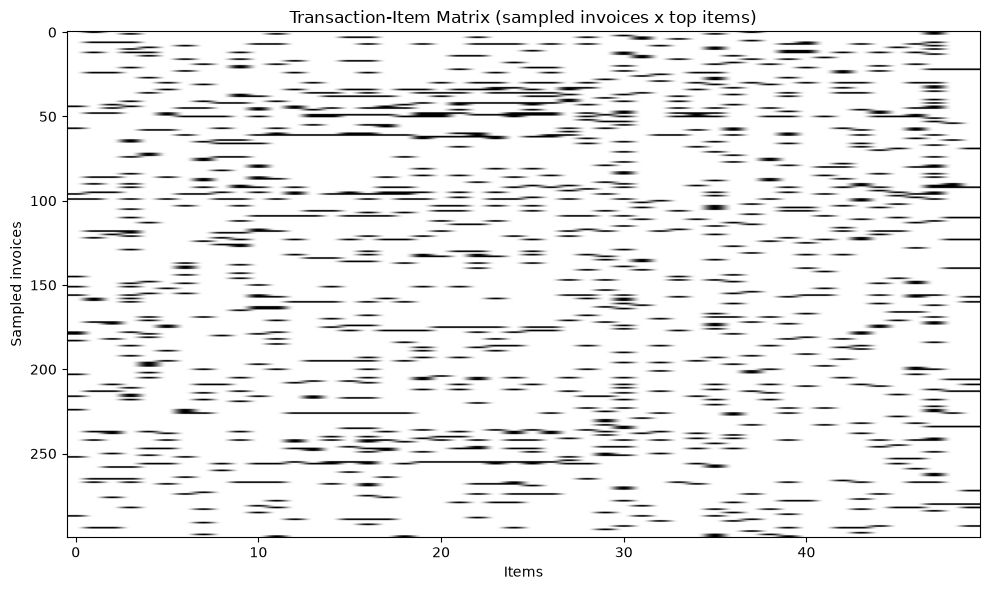

In [10]:
# Visualize a small slice like arules::image(txn): rows=transactions, cols=items
sample_rows = X.sample(n=min(300, X.shape[0]), random_state=SEED)

plt.figure(figsize=(10, 6))
plt.imshow(sample_rows.values.astype(int), aspect="auto", cmap="binary")
plt.title("Transaction-Item Matrix (sampled invoices x top items)")
plt.xlabel("Items")
plt.ylabel("Sampled invoices")
plt.tight_layout()
plt.show()

In [11]:
# Experiment with different TOP_K values and record downstream effects
top_k_values = [30, 50, 100]
results = []

for k in top_k_values:
    print(f"\n### TOP_K = {k} ###")
    top_items_k = item_counts.head(k).index
    filtered_k = basket_df[basket_df["Item"].isin(top_items_k)].copy()
    invoice_items_k = (
        filtered_k.groupby("InvoiceNo_str")["Item"]
        .apply(lambda s: sorted(set(s)))
        .rename("Basket")
        .reset_index()
    )

    # One-hot encode
    exploded_k = invoice_items_k.explode("Basket").dropna(subset=["Basket"]).copy()
    exploded_k["Basket"] = exploded_k["Basket"].astype(str)
    one_hot_k = pd.get_dummies(exploded_k["Basket"])
    X_k = one_hot_k.groupby(exploded_k["InvoiceNo_str"]).max().astype(bool)

    print("One-hot shape:", X_k.shape)

    # As a placeholder for "number of rules", run Apriori for a single min_support and count results
    from mlxtend.frequent_patterns import apriori, association_rules
    min_support = 0.05
    frequent_itemsets = apriori(X_k, min_support=min_support, use_colnames=True)
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.1)
    print(f"# Frequent itemsets: {len(frequent_itemsets)}")
    print(f"# Association rules: {len(rules)}")
    results.append({
        "TOP_K": k,
        "shape": X_k.shape,
        "n_itemsets": len(frequent_itemsets),
        "n_rules": len(rules)
    })

# Optionally create a results table
import pandas as pd
results_df = pd.DataFrame(results)
print("\nSummary of experiment:")
display(results_df)


### TOP_K = 30 ###
One-hot shape: (12585, 30)
# Frequent itemsets: 34
# Association rules: 8

### TOP_K = 50 ###
One-hot shape: (14414, 50)
# Frequent itemsets: 53
# Association rules: 6

### TOP_K = 100 ###
One-hot shape: (16074, 100)
# Frequent itemsets: 65
# Association rules: 2

Summary of experiment:


,TOP_K,shape,n_itemsets,n_rules
0,30,"(12585, 30)",34,8
1,50,"(14414, 50)",53,6
2,100,"(16074, 100)",65,2


## Execution questions
1) What does a dense block in the matrix plot suggest about certain items?      
A dense block means a group of items appears together across many sampled transactions. This can indicate popular products or recurring combinations, but popularity alone does not establish a meaningful association, so support and lift should also be examined.

2) Why is it dangerous to treat `Quantity` as irrelevant here?      
Quantity contains information about purchase behavior and distinguishes purchases from returns or zero-quantity records. Treating it as irrelevant before cleaning can allow invalid transactions to affect basket construction and rule statistics.

**Think like an ML Systems engineer**  
- Identify where *data leakage* could occur if you built rules on “all historical data” and evaluated on the same period. Propose a time-based split for validation.

### Step 5 — Baseline frequent itemsets with Apriori

### Coding questions
1) If you set `min_support` too high, what type of business insight do you miss?    
A high minimum support keeps only very common itemsets, so it can miss niche but potentially useful product combinations. The result can be statistically stable but less useful for long-tail recommendations.

2) If you set it too low, what system and statistical problems emerge?      
A very low minimum support can produce many itemsets and rules, increasing runtime and memory use. It can also produce rules based on very few transactions, making their support estimates unstable and increasing the chance of noisy patterns.

**Function/class selection + parameter exploration**
- Use: `mlxtend.frequent_patterns.apriori`  
- Explore parameters: `min_support`, `use_colnames`, `max_len`.

In [12]:
# If needed:
!pip -q install mlxtend

from mlxtend.frequent_patterns import apriori

MIN_SUPPORT = 0.02  # baseline; you will justify / tune
MAX_LEN = 3

t0 = time.time()
frequent_itemsets = apriori(
    X,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_LEN
)

runtime = time.time() - t0
frequent_itemsets = frequent_itemsets.sort_values("support", ascending=False)
print("Apriori runtime (sec):", round(runtime, 3))
print("#Frequent itemsets:", frequent_itemsets.shape[0])
frequent_itemsets.head(10)

Apriori runtime (sec): 0.037
#Frequent itemsets: 180


,support,itemsets
47,0.156792,(white hanging heart t-light holder)
16,0.145137,(jumbo bag red retrospot)
35,0.137991,(regency cakestand 3 tier)
30,0.116970,(party bunting)
23,0.108506,(lunch bag red retrospot)
3,0.100944,(assorted colour bird ornament)
39,0.096087,(set of 3 cake tins pantry design)
28,0.091578,(pack of 72 retrospot cake cases)
19,0.088317,(lunch bag black skull.)
27,0.086652,(natural slate heart chalkboard)


In [13]:
# Compute minimum invoice count implied by MIN_SUPPORT
min_count = int(np.ceil(MIN_SUPPORT * X.shape[0]))
print(f"MIN_SUPPORT={MIN_SUPPORT} implies minimum invoice count of {min_count} out of {X.shape[0]}")

MIN_SUPPORT=0.02 implies minimum invoice count of 289 out of 14414


### Execution questions
1) Why do we cap `max_len` for this lab?    
`max_len` limits the largest itemset considered. Without a cap, candidate generation can grow rapidly as combinations of items increase, which can make Apriori slow and memory-intensive. A small maximum length is also easier to interpret for this lab.

2) If the runtime is high, what are your first two mitigation strategies *without changing hardware*?   
First, reduce the search space by raising or tuning `min_support` and limiting `max_len` or the item vocabulary. Second, use a more scalable algorithm such as FP-Growth and reuse cached one-hot or intermediate artifacts.

**Think like an ML Systems engineer**  
- Where would you cache intermediate artifacts (one-hot matrix, frequent itemsets) in a pipeline, and what versioning key would you use?    
Cache the cleaned transaction table, one-hot matrix, frequent itemsets, and final rules as versioned intermediate artifacts. A useful cache key includes the dataset checksum, cleaning/preprocessing version, item vocabulary or TOP_K, min_support, max_len, algorithm, and code version.

### Step 6 — Association rule generation + interpretation (support/confidence/lift)

#### Coding questions
1) Why can high confidence be misleading when the consequent is very common?    
High confidence can occur simply because the consequent is common. If 80% of transactions contain the consequent, many unrelated antecedents can have high confidence. Lift compares the observed co-occurrence with the baseline frequency of the consequent and helps reveal this popularity effect.  

2) What does lift > 1 mean operationally for cross-sell recommendations?    
Lift greater than 1 means the antecedent and consequent occur together more often than expected from the consequent's overall frequency. For cross-sell, that can identify combinations worth testing, but it is an association rather than proof that recommending one item causes purchase of the other.

**Function/class selection + parameter exploration**
- Use: `mlxtend.frequent_patterns.association_rules`  
- Explore parameters: `metric` and `min_threshold`; discuss filtering by `lift` vs `confidence`.

In [14]:
from mlxtend.frequent_patterns import association_rules

MIN_LIFT = 1.2
rules = association_rules(
    frequent_itemsets,
    metric="lift",
    min_threshold=MIN_LIFT,
    num_itemsets=X.shape[0],
)

rules = rules.sort_values(["lift", "confidence", "support"], ascending=False)
print("#Rules (lift >= {:.2f}):".format(MIN_LIFT), rules.shape[0])
rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10)

#Rules (lift >= 1.20): 338


,antecedents,consequents,support,confidence,lift
102,"(roses regency teacup and saucer, regency cake...",(green regency teacup and saucer),0.028306,0.777143,11.036194
103,(green regency teacup and saucer),"(roses regency teacup and saucer, regency cake...",0.028306,0.401970,11.036194
101,"(green regency teacup and saucer, regency cake...",(roses regency teacup and saucer),0.028306,0.801572,10.838513
104,(roses regency teacup and saucer),"(green regency teacup and saucer, regency cake...",0.028306,0.382739,10.838513
2,(green regency teacup and saucer),(roses regency teacup and saucer),0.053282,0.756650,10.231104
3,(roses regency teacup and saucer),(green regency teacup and saucer),0.053282,0.720450,10.231104
10,(alarm clock bakelike green),(alarm clock bakelike red),0.044401,0.653061,8.956446
11,(alarm clock bakelike red),(alarm clock bakelike green),0.044401,0.608944,8.956446
258,"(jumbo bag pink polkadot, jumbo shopper vintag...",(jumbo storage bag suki),0.021437,0.660256,8.037953
263,(jumbo storage bag suki),"(jumbo bag pink polkadot, jumbo shopper vintag...",0.021437,0.260980,8.037953


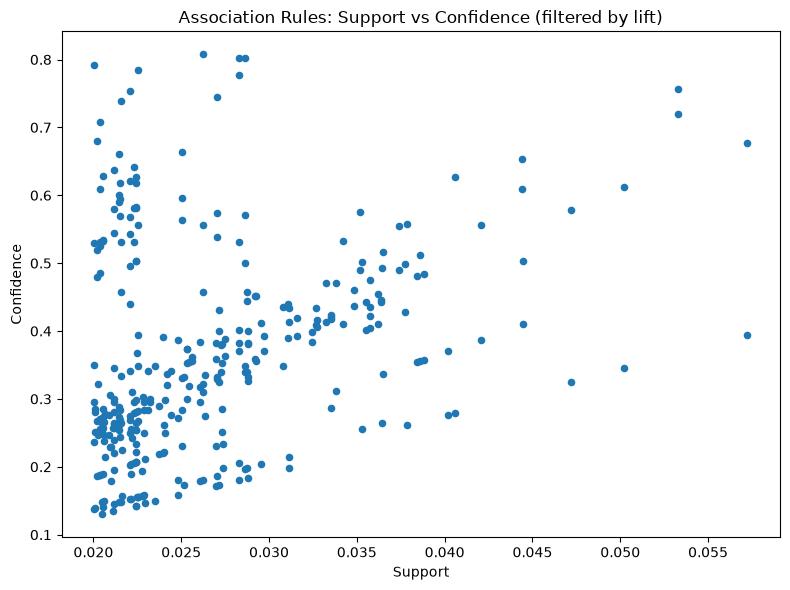

In [15]:
plt.figure(figsize=(8, 6))
plt.scatter(rules["support"], rules["confidence"], s=20)
plt.title("Association Rules: Support vs Confidence (filtered by lift)")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.tight_layout()
plt.show()

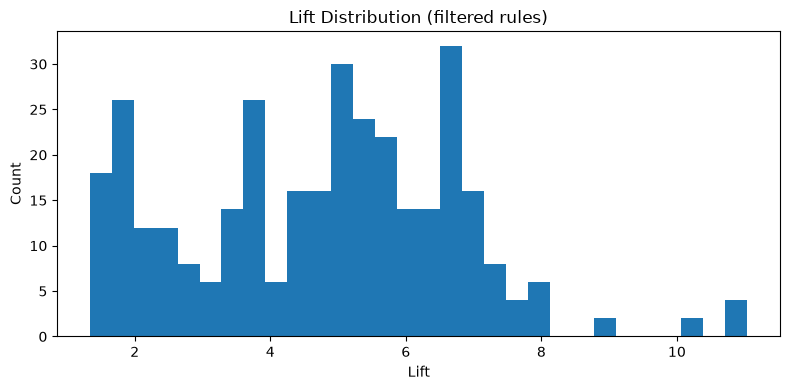

In [16]:
plt.figure(figsize=(8, 4))
plt.hist(rules["lift"], bins=30)
plt.title("Lift Distribution (filtered rules)")
plt.xlabel("Lift")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [17]:
# Compute all rules without filtering on lift
rules_all = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.1,  # low threshold to get many rules
    num_itemsets=X.shape[0],
)

# Filter for "misleading" rules: lift very close to 1 (not truly associated)
misleading_rules = rules_all[rules_all["lift"] < 1.05].copy()

# Sort by descending confidence and select top 10
top_misleading = misleading_rules.sort_values(by="confidence", ascending=False).head(10)

print("Top 10 'misleading' rules by confidence (lift < 1.05):")
display(top_misleading[["antecedents", "consequents", "support", "confidence", "lift"]])

Top 10 'misleading' rules by confidence (lift < 1.05):


,antecedents,consequents,support,confidence,lift


**Post-execution questions**
1) Choose one top-lift rule and propose a business action. What is one risk?    
A top-lift rule could be used as a candidate cross-sell rule, such as showing the consequent when the antecedent appears in a basket. One risk is that a high lift may be based on a small number of transactions, so the rule should be checked for adequate support and monitored after deployment.

2) What limitation prevents you from calling these “causal effects”?    
Association rules are observational patterns. They do not control for confounding variables or establish that one item caused another purchase. Causal effects would require a causal design such as an experiment or an appropriate causal-inference method.

3) Systems question: what is the inference-time cost of a rule engine vs a model?   
A rule engine can be very cheap at inference if rules are indexed by antecedent and only matching rules are retrieved. A model requires feature construction and scoring, but its cost can also be predictable. The actual tradeoff depends on rule count, lookup structure, model size, feature latency, and cache behavior.

**Think like an ML Systems engineer**  
- What would you log in production for each fired rule (rule id, timestamp, basket context, user segment, outcome) to enable monitoring and A/B validation?     
For each fired rule, log a stable rule ID, timestamp, rule version, antecedent and consequent IDs, support/confidence/lift at training time, basket context needed for debugging, relevant non-sensitive segment information, whether the recommendation was shown, and the later outcome. Avoid logging unnecessary personal data.

### Step 7 — Improvement step: FP-Growth and threshold tuning + systems comparison

**Coding questions**
1) Why might Apriori be slow on large item vocabularies?    
Apriori repeatedly generates candidate itemsets and scans the transaction structure to count their support. As the item vocabulary grows, the number of possible combinations can grow rapidly, producing high computational and memory costs.

2) What tradeoff does FP-Growth make (data structure, memory, implementation complexity)?   
FP-Growth compresses transactions into an FP-tree and mines patterns without generating the same breadth of explicit candidates as Apriori. This can improve runtime, but the tree can require substantial memory and the implementation is more complex than the simple candidate-generation approach.

**Function/class selection + parameter exploration**
- Use: `mlxtend.frequent_patterns.fpgrowth`  
- Explore: keeping `min_support` fixed and comparing runtime; discuss memory and scaling.

In [18]:
from mlxtend.frequent_patterns import fpgrowth

t0 = time.time()
fi_fp = fpgrowth(X, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
rt_fp = time.time() - t0

print("FP-Growth runtime (sec):", round(rt_fp, 3))
print("#Frequent itemsets (FP):", fi_fp.shape[0])

print("Top-5 supports (Apriori):", frequent_itemsets["support"].head(5).tolist())
print("Top-5 supports (FP):", fi_fp.sort_values("support", ascending=False)["support"].head(5).tolist())

FP-Growth runtime (sec): 0.09
#Frequent itemsets (FP): 180
Top-5 supports (Apriori): [0.1567920077702234, 0.14513667267933952, 0.13799084223671432, 0.1169696128763702, 0.10850561953656168]
Top-5 supports (FP): [0.1567920077702234, 0.14513667267933952, 0.13799084223671432, 0.1169696128763702, 0.10850561953656168]


In [19]:
# Simple benchmark: Apriori vs FP-Growth for TOP_K=50 and TOP_K=100

import pandas as pd

benchmarks = []

for top_k in [50, 100]:
    # Determine min_support for top_k
    # Compute itemset supports via apriori with a very low min_support, then pick the support that yields at least top_k itemsets
    apriori_all = apriori(X, min_support=0.001, use_colnames=True, max_len=MAX_LEN)
    apriori_sorted = apriori_all.sort_values('support', ascending=False)
    if apriori_sorted.shape[0] < top_k:
        actual_k = apriori_sorted.shape[0]
        min_support_k = apriori_sorted['support'].min()
    else:
        actual_k = top_k
        min_support_k = apriori_sorted.iloc[top_k-1]['support'] if apriori_sorted.shape[0] >= top_k else apriori_sorted['support'].min()

    # Apriori timing using found min_support
    t0 = time.time()
    apriori_result = apriori(X, min_support=min_support_k, use_colnames=True, max_len=MAX_LEN)
    apriori_result = apriori_result.sort_values('support', ascending=False).head(top_k)
    apriori_time = time.time() - t0

    # FP-Growth with same min_support
    t1 = time.time()
    fp_result = fpgrowth(X, min_support=min_support_k, use_colnames=True, max_len=MAX_LEN)
    fp_result = fp_result.sort_values('support', ascending=False).head(top_k)
    fp_time = time.time() - t1

    benchmarks.append({
        'TOP_K': top_k,
        'min_support': round(float(min_support_k), 5),
        'apriori_count': apriori_result.shape[0],
        'apriori_time': round(apriori_time, 3),
        'fp_count': fp_result.shape[0],
        'fp_time': round(fp_time, 3)
    })

df_bench = pd.DataFrame(benchmarks)
print(df_bench)

# For clarity, column naming:
# 'apriori_count': number of itemsets returned by Apriori for top K,
# 'apriori_time': runtime for Apriori
# 'fp_count': number of itemsets returned by FP-Growth for top K,
# 'fp_time': runtime for FP-Growth

   TOP_K  min_support  apriori_count  apriori_time  fp_count  fp_time
0     50      0.06043             50         0.033        50    0.071
1    100      0.02831            100         0.031       100    0.082


### Execution questions
1) If FP-Growth is faster here, why might a team still choose Apriori?  
A team might still choose Apriori because it is straightforward to understand, implement, debug, and explain. For a small dataset, its simplicity may outweigh the performance benefit of a more complex method.

2) In a real system, would you recompute rules daily, hourly, or streaming? Justify.    
The schedule should depend on how quickly purchasing behavior changes and how much compute is available. For a normal retail catalog, daily or hourly batch recomputation is often easier to operate than streaming. Streaming is more appropriate when near-real-time behavior is essential and the added infrastructure is justified.

**Think like an ML Systems engineer**  
- Identify one monitoring signal that indicates “rule quality regression” after deployment (e.g., lift decay, CTR drop, firing-rate shift). Propose an alert threshold.     
One useful signal is the lift of rules that are actually being fired. For example, an alert could be triggered when median production lift for a monitored rule family falls by more than 20% from its validation baseline for several consecutive evaluation windows. The threshold should be calibrated using historical variability rather than treated as universal.

### Step 8 — Sequence construction

**Pre-coding questions**
1) Why is “association within a transaction” different from “sequence across transactions”?     
Association mining is used to treat items in the same transaction as co-occurring, without requiring one item to happen before another. Sequence mining preserves event order, so a pattern such as A -> B means B occurs later in the sequence. This makes sequence rules useful for next-event behavior rather than just co-purchase.

2) What is a subsequence and how does it relate to support in sequence mining?      
A subsequence is an ordered pattern that appears within a longer sequence while preserving event order. Its support is the fraction of customer sequences that contain that ordered pattern. Higher support means the pattern appears across more customers in the sequence database.

3) What failure mode occurs if timestamps are not consistently parsed/time-zoned?       
Inconsistent timestamp parsing or time zones can place events in the wrong chronological order. That can create false transitions, hide real transitions, and change the sequential patterns discovered.

**Function/class selection + parameter exploration**
- Use: `groupby`, `sort_values`, `apply`, `drop_duplicates`  
- Explore: defining an “event boundary” (InvoiceNo as a transaction step) vs alternatives (day-level sessions).

In [20]:
# Build sequences as ordered lists of "event tokens".
# Here: each event token is a SMALL tuple of top items purchased in an invoice.

seq_df["Item"] = seq_df["Description"].astype(str).str.strip().str.lower()
seq_df = seq_df[seq_df["Item"].isin(top_items)].copy()

inv_baskets = (
    seq_df.groupby(["CustomerID", "InvoiceNo_str"], as_index=False)
    .agg({
        "InvoiceDate": "min",
        "Item": lambda s: sorted(set(s))
    })
)

# Keep only small baskets to form manageable "event tokens" (top 3 items within invoice)
inv_baskets["Event"] = inv_baskets["Item"].apply(lambda items: tuple(items[:3]))

inv_baskets = inv_baskets.sort_values(["CustomerID", "InvoiceDate", "InvoiceNo_str"])

customer_sequences = inv_baskets.groupby("CustomerID")["Event"].apply(list)

MIN_EVENTS = 3
seq_db = [seq for seq in customer_sequences if len(seq) >= MIN_EVENTS]

print("#Customer sequences:", len(seq_db))
if len(seq_db) > 0:
    print("Example sequence:", seq_db[0][:5])
else:
    print("No sequences available after filtering; adjust TOP_K or MIN_EVENTS.")

#Customer sequences: 1539
Example sequence: [('alarm clock bakelike green', 'alarm clock bakelike red'), ('alarm clock bakelike green', 'alarm clock bakelike red', 'regency cakestand 3 tier'), ('regency cakestand 3 tier', 'roses regency teacup and saucer'), ('alarm clock bakelike red', 'rabbit night light'), ('alarm clock bakelike red', 'regency cakestand 3 tier')]


In [21]:
# Alternative event abstraction: day-level baskets (group by date instead of invoice).
# Each "event" is now a tuple of (up to top 3) items bought by a customer in a single calendar day.

# 1. Extract date from InvoiceDate.
seq_df["date"] = seq_df["InvoiceDate"].dt.date

# 2. Group by CustomerID and date, collect up to top 3 frequent items that appear in that day.
# We'll preserve ordering by global frequency as in the original code.

# Convert top_items to a list if it's not already to ensure .index() is available
top_items_list = list(top_items)

day_baskets = (
    seq_df.groupby(["CustomerID", "date"], as_index=False)
    .agg({
        "InvoiceDate": "min",  # To preserve temporal order
        # Use top_items_list, which is guaranteed to have an 'index' method
        "Item": lambda s: sorted(set(s), key=lambda x: top_items_list.index(x))  # sort by frequency in top_items
    })
)

day_baskets["Event"] = day_baskets["Item"].apply(lambda items: tuple(items[:3]))

# Sort by CustomerID and day to ensure chronological order.
day_baskets = day_baskets.sort_values(["CustomerID", "InvoiceDate", "date"])

customer_sequences = day_baskets.groupby("CustomerID")["Event"].apply(list)

MIN_EVENTS = 3
seq_db = [seq for seq in customer_sequences if len(seq) >= MIN_EVENTS]

print("#Customer sequences:", len(seq_db))
if len(seq_db) > 0:
    print("Example sequence:", seq_db[0][:5])
else:
    print("No sequences available after filtering; adjust TOP_K or MIN_EVENTS.")

#Customer sequences: 1506
Example sequence: [('alarm clock bakelike red', 'alarm clock bakelike green'), ('regency cakestand 3 tier', 'alarm clock bakelike red', 'alarm clock bakelike green'), ('regency cakestand 3 tier', 'roses regency teacup and saucer'), ('alarm clock bakelike red', 'rabbit night light'), ('regency cakestand 3 tier', 'alarm clock bakelike red')]


### Execution questions
1) How does your event definition impact the patterns you can discover?     
The event definition determines what counts as a step. Invoice-level events preserve individual transactions, while day-level events merge purchases made on the same day. Changing the boundary can merge or split patterns, so the definition should match the business question and be documented.

2) Systems question: what is the memory cost driver in `seq_db`?        
The main memory drivers are the number of customer sequences, the number of events per sequence, and the size of each event token. Keeping full strings and large event tuples consumes more memory than compact integer IDs.

**Think like an ML Systems engineer**  
- Write one validation check that ensures sequence ordering is correct *per customer* before mining.    
After sorting, verify for every customer that `InvoiceDate` is monotonically increasing. A simple check is to group by customer and test `is_monotonic_increasing`; any failures should be investigated before sequence mining.

### Step 9 — Sequential pattern mining with PrefixSpan and sequential rules

#### Coding questions
1) Why is candidate generation expensive in GSP and how does PrefixSpan avoid it conceptually?      
GSP can become expensive because it repeatedly generates and evaluates many candidate sequences as pattern length grows. PrefixSpan instead grows patterns by projecting the database around observed prefixes, reducing the need to enumerate the full candidate space explicitly.

2) What is the operational meaning of “support” in sequence mining?     
Sequence support is the fraction of customer sequences containing a particular ordered pattern. Operationally, it estimates how common that behavior is across customers and helps distinguish broadly useful patterns from rare sequences.

**Function/class selection + parameter exploration**
- Use: `prefixspan.PrefixSpan`  
- Explore: `min_support` as an absolute count vs fraction; explain how you set it for stability vs novelty.

In [22]:
# If needed:
!pip -q install prefixspan

from prefixspan import PrefixSpan


def format_event_token(event_token):
    if isinstance(event_token, (tuple, list)):
        return "{" + ",".join(map(str, event_token)) + "}"
    return "{" + str(event_token) + "}"


if len(seq_db) == 0:
    patterns = []
    pat_df = pd.DataFrame(columns=["support_count", "support", "length", "pattern"])
    print("No sequence data to mine. Skipping PrefixSpan.")
else:
    ps = PrefixSpan(seq_db)

    min_sup_frac = 0.02
    min_sup = max(1, int(np.ceil(min_sup_frac * len(seq_db))))
    print("min_sup (count):", min_sup, "out of", len(seq_db))

    patterns = ps.frequent(min_sup)

    # patterns: list of (support_count, pattern_as_list)
    patterns_sorted = sorted(patterns, key=lambda x: (x[0], len(x[1])), reverse=True)

    pat_rows = []
    for sup_count, pat in patterns_sorted[:30]:
        pat_rows.append({
            "support_count": sup_count,
            "support": sup_count / len(seq_db),
            "length": len(pat),
            "pattern": " -> ".join([format_event_token(e) for e in pat]),
        })

    pat_df = pd.DataFrame(pat_rows)

pat_df.head(10)

min_sup (count): 31 out of 1506


,support_count,support,length,pattern
0,110,0.073041,1,{white hanging heart t-light holder}
1,101,0.067065,1,{postage}
2,94,0.062417,1,{paper chain kit 50's christmas}
3,88,0.058433,1,{regency cakestand 3 tier}
4,78,0.051793,1,{assorted colour bird ornament}
5,74,0.049137,1,{rabbit night light}
6,68,0.045153,1,{party bunting}
7,62,0.041169,1,{victorian glass hanging t-light}
8,55,0.036521,1,{rex cash+carry jumbo shopper}
9,54,0.035857,2,{postage} -> {postage}


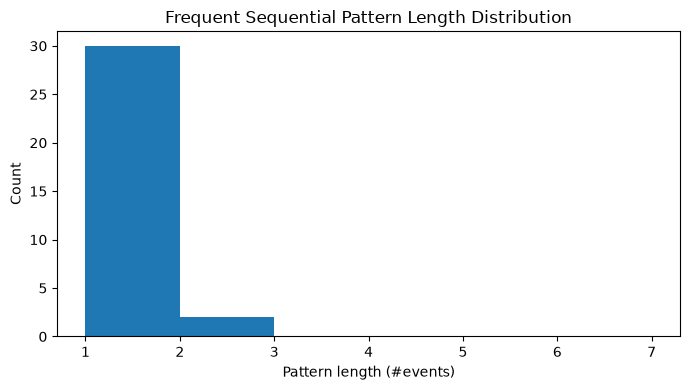

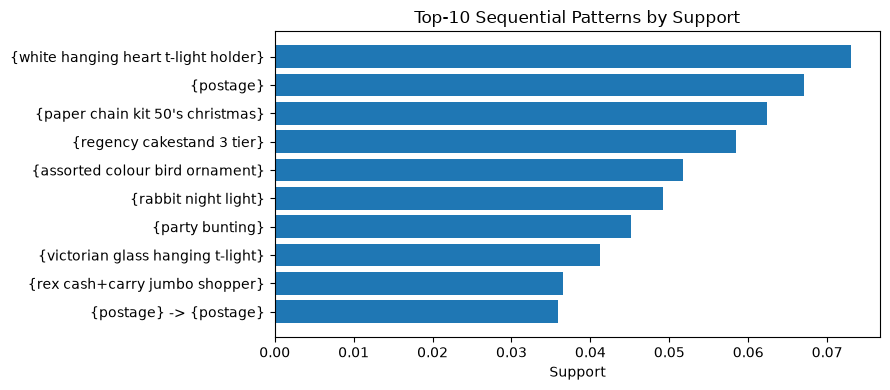

In [23]:
plt.figure(figsize=(7, 4))
plt.hist([len(p[1]) for p in patterns], bins=range(1, 8))
plt.title("Frequent Sequential Pattern Length Distribution")
plt.xlabel("Pattern length (#events)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
top10 = pat_df.head(10).iloc[::-1]
plt.barh(top10["pattern"], top10["support"])
plt.title("Top-10 Sequential Patterns by Support")
plt.xlabel("Support")
plt.tight_layout()
plt.show()

In [24]:
# Derive simple sequential rules (prefix -> next event)
if len(seq_db) == 0 or len(patterns) == 0:
    seq_rules = pd.DataFrame(columns=["prefix", "next", "support", "confidence", "lift"])
    print("No sequential patterns available for rule derivation.")
else:
    support_map = {tuple(pat): sup_count / len(seq_db) for sup_count, pat in patterns}

    rule_rows = []
    for sup_count, pat in patterns:
        if len(pat) < 2:
            continue
        prefix = tuple(pat[:-1])
        next_event = (pat[-1],)
        full = tuple(pat)

        sup_full = support_map.get(full, 0.0)
        sup_prefix = support_map.get(prefix, 0.0)
        sup_next = support_map.get(tuple(next_event), 0.0)

        if sup_prefix == 0:
            continue

        conf = sup_full / sup_prefix
        lift = conf / sup_next if sup_next > 0 else np.nan

        rule_rows.append({
            "prefix": " -> ".join([format_event_token(e) for e in prefix]),
            "next": format_event_token(pat[-1]),
            "support": sup_full,
            "confidence": conf,
            "lift": lift,
        })

    seq_rules = pd.DataFrame(rule_rows, columns=["prefix", "next", "support", "confidence", "lift"])
    if not seq_rules.empty:
        seq_rules = seq_rules.sort_values(["lift", "confidence", "support"], ascending=False)

seq_rules.head(10)

,prefix,next,support,confidence,lift
0,{postage},{postage},0.035857,0.534653,7.972160
1,{white hanging heart t-light holder},{white hanging heart t-light holder},0.023240,0.318182,4.356198


In [25]:
# Filter rules by support >= 0.01 and confidence >= 0.3
filtered_rules = seq_rules[(seq_rules['support'] >= 0.01) & (seq_rules['confidence'] >= 0.3)]

# Sort by lift (descending), then confidence, then support
top5_rules = filtered_rules.sort_values(['lift', 'confidence', 'support'], ascending=False).head(5)

print(top5_rules)

# Provide business interpretations for each rule
for i, row in top5_rules.iterrows():
    print(f"\nRule {i+1}: If event(s) {row['prefix']} occur, likely next event is {row['next']} (support={row['support']:.3f}, confidence={row['confidence']:.3f}, lift={row['lift']:.2f})")
    print("Business interpretation: ", end="")
    # A simple interpretation template you can expand
    print(f"Customers who bought {row['prefix']} are {row['confidence']:.0%} likely to subsequently buy {row['next']}, which occurs {row['lift']:.1f} times more frequently than expected by chance.")

                                 prefix                                  next   support  confidence      lift
0                             {postage}                             {postage}  0.035857    0.534653  7.972160
1  {white hanging heart t-light holder}  {white hanging heart t-light holder}  0.023240    0.318182  4.356198

Rule 1: If event(s) {postage} occur, likely next event is {postage} (support=0.036, confidence=0.535, lift=7.97)
Business interpretation: Customers who bought {postage} are 53% likely to subsequently buy {postage}, which occurs 8.0 times more frequently than expected by chance.

Rule 2: If event(s) {white hanging heart t-light holder} occur, likely next event is {white hanging heart t-light holder} (support=0.023, confidence=0.318, lift=4.36)
Business interpretation: Customers who bought {white hanging heart t-light holder} are 32% likely to subsequently buy {white hanging heart t-light holder}, which occurs 4.4 times more frequently than expected by chance.


### Execution questions
1) How should you interpret a high-lift sequential rule vs a high-lift association rule?    
A high-lift association rule means two items co-occur more often than expected, with no required time direction. A high-lift sequential rule means an ordered prefix is followed by a later event more often than expected. The sequential rule therefore carries temporal information, although it still does not establish causality. 


2) What is one limitation of your sequence encoding in this lab?    
The lab represents each event using only a small tuple of top items. This loses quantities, full basket contents, exact time gaps, and less-popular products, so some real sequential relationships cannot be discovered.


3) Systems question: what would you monitor to detect drift in sequences?   
Monitor event rates, average time between events, sequence length, transition frequencies, next-event distributions, and the support/lift of important sequential rules. Changes from the training baseline can indicate behavioral drift or upstream data problems.


**Think like an ML Systems engineer**  
- If you had to scale this to 100M events, what would you change first: representation (ints), algorithm (Spark PrefixSpan), or sampling? Justify.  
I would first move to compact integer representations because they reduce memory and data-transfer costs while preserving the same mining logic. For 100M events, I would then use a distributed implementation such as Spark PrefixSpan if a single machine could no longer handle the workload. Sampling can be useful for exploratory analysis, but it may miss rare patterns that matter operationally.

**End of Lab**